# Data Science Vignette
## Regularized Least Squares - Ridge Regression

Regularized least squares is a linear prediction method with $\ell_2^2$ regularization that corresponds to the optimization problem:

$$\min_\beta f(\beta) := \frac{1}{2}\|y - X\beta\|^2_2 + \frac{\lambda}{2}\|\beta\|^2_2$$
where:

- $X \in \mathbb{R}^{k \times d}$ is the data matrix
- $y \in \mathbb{R}^k$ is the output vector
- $\beta \in \mathbb{R}^d$ are the weights we want to learn
- $\lambda > 0$ is the regularization parameter

The objective $f$ is convex and differentiable. By the Chain Rule, we obtain gradient:

$$\nabla_\beta f(\beta) = -X^\top (y-X\beta) + \lambda \beta$$

The first pieces of code we need are functions returning the $f(\beta)$ and $\nabla f(\beta)$.

In [ ]:
import numpy as np
def ridge_regression_objective(beta, X, y, lambda_):
    """Ridge regression objective function."""
    return (1/2) * np.sum((y - X @ beta)**2) + (lambda_/2) * np.sum(beta**2)

def ridge_regression_gradient(beta, X, y, lambda_):
    """Gradient of ridge regression objective."""
    return -X.T @ (y - X @ beta) + lambda_ * beta

## Optimization Algorithm - Gradient Descent with Goldstein Line Search

<!-- This Jupyter notebook is an introduction to gradient descent optimization with line search methods, specifically focusing on the Goldstein Line Search technique. We'll apply this to a ridge regression problem to demonstrate its practical utility.

## Problem Introduction
Most machine learning problems can be formulated as finding the parameters that minimize some objective function:

$$\min_{x\in \mathbb{R}^n}f(x)$$

where $f: \mathbb{R}^n \rightarrow \mathbb{R}$ is the objective function. In optimization, we want to find $x^*$ such that:

$$x^* = \arg\min_{x\in \mathbb{R}^n} f(x)$$

For differentiable functions, a necessary condition for an optimal point is $\nabla f(x^*) = 0$. However, finding this point analytically is often not possible, which is why we use iterative methods like gradient descent.

## Gradient Descent Method -->

The gradient descent algorithm uses the following update rule:

$$x_{k+1} = x_k - \alpha_k\nabla f(x_k)$$

where:

- $x_k$ is the current point

- $\alpha_k$ is the step size (or learning rate)

- $\nabla f(x_k)$ is the gradient of $f$ at point $x_k$

The challenge is selecting an appropriate step size $\alpha_k$. If it's too small, convergence is slow. If it's too large, the algorithm might overshoot the minimum or even diverge.

Here is an illustration:

<img src="https://upload.wikimedia.org/wikipedia/commons/thumb/f/ff/Gradient_descent.svg/1280px-Gradient_descent.svg.png" alt="Gradient Descent Steps" width="500"/>


Now, let's implement a fixed-stepsize gradient descent method.

In [ ]:
import numpy as np
def gradient_descent_fixed_step(f, grad_f, x0, alpha=0.01, tol=1e-6, max_iter=1000):
    """Gradient descent with fixed step size."""
    x = x0.copy()
    f_vals = [f(x)]

    for i in range(max_iter):
        grad = grad_f(x)

        # Check stopping criterion
        if np.linalg.norm(grad) < tol:
            break

        # Update
        x = x - alpha * grad
        f_vals.append(f(x))

    return x, np.array(f_vals)


Let's try to apply the fixed-stepsize gradient method to a simple problem for $f: \mathbb{R}^2 \to \mathbb{R}$:
$$f(x^{(1)},x^{(2)}) = \frac{1}{2}(x^{(1)})^2 + \frac{1}{4}(x^{(2)})^4 - \frac{1}{2}(x^{(2)})^2$$

The function is not convex, but it is differentiable:
$$\nabla f(x^{(1)},x^{(2)}) = [x^{(1)}, (x^{(2)})^3 - x^{(2)}]^\top$$

Observe, there are three points $(x^{(1)},x^{(2)})$ that satisfy $\nabla f(x^{(1)},x^{(2)}) = 0$: $\{(0,0), (0, -1), (0,1)\}$.

Here is a visualization of $z = f(x,y)$:
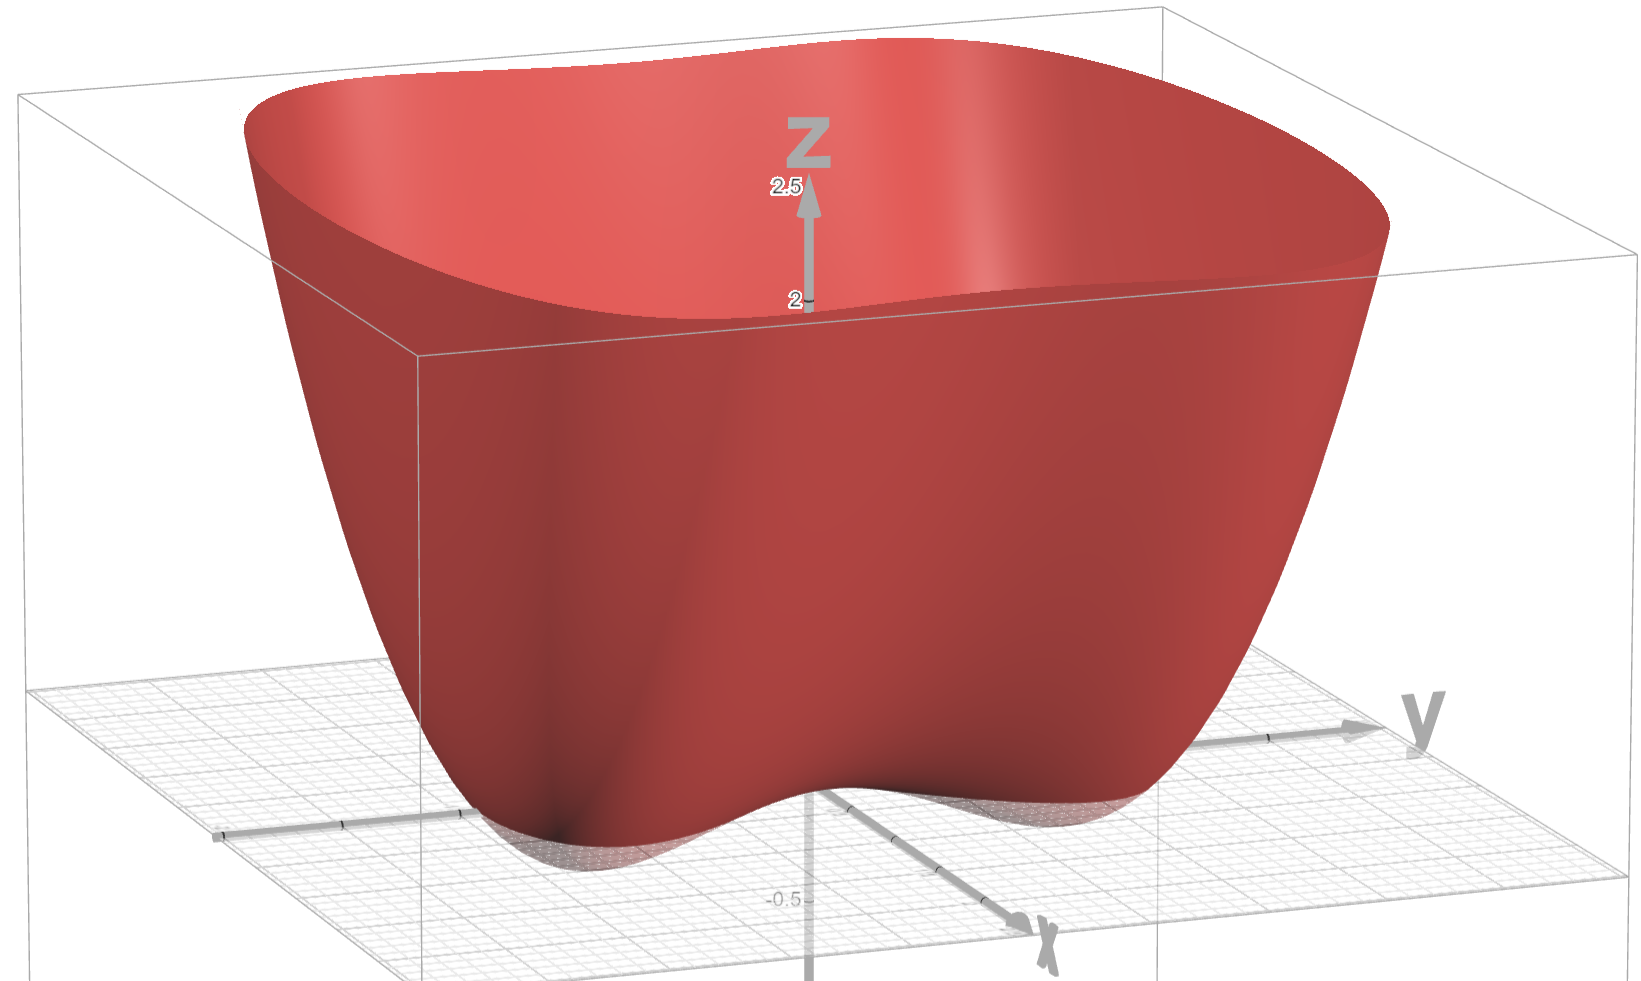

In [ ]:
import numpy as np

func = lambda x: (1/2)*(x[0] ** 2) + (1/4)*(x[1] ** 4) - (1/2)*(x[1] ** 2)
grad_func = lambda x: np.array([x[0], (x[1] ** 3) - x[1]])

def optimize_func(init_x: float, init_y: float):
  x0 = np.array([init_x, init_y])
  optimizer, _ = gradient_descent_fixed_step(func, grad_func, x0, alpha=0.01)
  opt_value = func(optimizer)
  print("Optimzer found at: ", np.around(optimizer, decimals=4))
  print("Optimal value found: ", np.around(opt_value, decimals=4))

import ipywidgets
ipywidgets.interact(optimize_func,
  init_x=ipywidgets.FloatSlider(min=-5.0, max=5.0, step=0.1, value=1.0),
  init_y=ipywidgets.FloatSlider(min=-5.0, max=5.0, step=0.1, value=1.0),
);


interactive(children=(FloatSlider(value=1.0, description='init_x', max=5.0, min=-5.0), FloatSlider(value=1.0, …

We will now try appying the fixed-stepsize gradient descent to a 3-point regression problem, with the ridge regression function $f(\beta)$.

In [ ]:
from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

def load_regression_data(num_samples: int, test: bool = True):
  # Generate synthetic data
  np.random.seed(42)
  X, y = make_regression(n_samples=num_samples, n_features=20, noise=0.1, random_state=42)

  if test:
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
  else:
    X_train = X
    y_train = y
    X_test, y_test = None, None

  # Normalize features (important for gradient-based methods)
  X_mean = X_train.mean(axis=0)
  X_std = X_train.std(axis=0)
  X_train = (X_train - X_mean) / X_std

  if test:
    X_test = (X_test - X_mean) / X_std

  return X_train, X_test, y_train, y_test

def plot_optimization_fixed(num_samples: int = 3, step_size: float = 0.01):
  X_train, _, y_train, _ = load_regression_data(num_samples=num_samples, test=False)

  # Define ridge regression with fixed data
  lambda_ = 0.1

  def f(beta):
      return ridge_regression_objective(beta, X_train, y_train, lambda_)

  def grad_f(beta):
      return ridge_regression_gradient(beta, X_train, y_train, lambda_)

  # Initial guess, beta = 0
  beta0 = np.zeros(X_train.shape[1])

  # Run gradient descent with fixed step size
  beta_fixed, f_vals_fixed = gradient_descent_fixed_step(
      f, grad_f, beta0, alpha=step_size, tol=1e-6, max_iter=50
  )

  plt.figure(figsize=(12, 6))
  plt.semilogy(f_vals_fixed, label='GD + Fixed Step Size')
  plt.xlabel('Iteration')
  plt.ylabel('Objective Function Value (log scale)')
  plt.title('Convergence Plot')
  plt.legend()
  plt.grid(True)
  plt.show()

ipywidgets.interact(plot_optimization_fixed,
  num_samples=3,
  step_size=ipywidgets.FloatSlider(min=0.001, max=0.1, step=0.001, value=0.001),
);


interactive(children=(IntSlider(value=3, description='num_samples', max=9, min=-3), FloatSlider(value=0.001, d…

As you can see, the algorithm diverges to inifnity if the stepsize is too large.

## Line Search Methods

Line search methods adaptively determine the step size at each iteration to ensure sufficient decrease in the objective function. The general procedure is:

1. Determine a descent direction: $-\nabla f(x_k)$

2. Find an appropriate step size $\alpha_k$

3. Update: $x_{k+1} = x_k - \alpha_k\nabla f(x_k)$

### Goldstein Line Search

The Goldstein line search is a method for determining the step size that ensures sufficient decrease in the objective function.

First, observe the first-order Taylor approximation of the gradient descent iterates:

$$f(x_{k+1}) = f(x_k - \alpha_k\nabla f(x_k))
\approx f(x_k) + \langle\nabla f(x_k), - \alpha_k\nabla f(x_k)\rangle
= f(x_k) - \alpha_k \|\nabla f(x_k)\|_2^2 $$

Thus, if the linearization is accurate, we expect the function value to decrease by $\alpha_k \|\nabla f(x_k)\|_2^2$. Since the linearization may be inaccurate, we only require a fraction of the decrease: $c\alpha_k \|\nabla f(x_k)\|_2^2$, with $c \in (0,0.5)$.

This way, we check for sufficient decrease by ensuring the following condition at each step:

$$f(x_k - \alpha_k\nabla f(x_k)) \leq f(x_k) - c\alpha_k \|\nabla f(x_k)\|_2^2$$

If the sufficient decrease condition is not satisfied, we multiply stepsize by a reduction factor $\tau \in (0,1)$, in hopes of improving linear approximation with smaller steps.

We can implement Goldstein line search in code as follows.

In [ ]:
import numpy as np
def goldstein_line_search(f, grad_f, x, alpha=1.0, c=0.1, tau=0.5, max_iter=100):
    """
    Goldstein line search to find an appropriate step size.

    Parameters:
    f: Function to minimize
    grad_f: Gradient of the function
    x: Current point
    alpha: Initial step size
    c: Constant in (0, 0.5)
    tau: Reduction factor in (0, 1)
    max_iter: Maximum iterations

    Returns:
    alpha: Step size satisfying Goldstein conditions
    """
    f0 = f(x)  # Function value at current point
    grad0 = grad_f(x) # Gradient value at current point
    grad0_norm_sq = np.sum(grad0 ** 2)  # Gradient norm squared

    iter_count = 0
    while iter_count < max_iter:
        # Check if we have insufficient decrease
        if f(x - alpha * grad0) > f0 - c * alpha * grad0_norm_sq:
            # Reduce step size
            alpha = tau * alpha
            iter_count += 1
        else:
            # Found appropriate step size
            return alpha

    return alpha  # Return last alpha if max iterations reached


## Gradient Descent with Line Search
Now, let's implement gradient descent with our Goldstein line search:

In [ ]:
def gradient_descent_with_line_search(f, grad_f, x0,
                                     tol=1e-6, max_iter=1000,
                                     ls_params=None):
    """
    Gradient descent with line search.

    Parameters:
    f: Function to minimize
    grad_f: Gradient of the function
    x0: Initial point
    tol: Tolerance for stopping criterion
    max_iter: Maximum iterations
    ls_params: Parameters for line search

    Returns:
    x: Solution
    f_vals: Function values at each iteration
    """
    if ls_params is None:
        ls_params = {}

    x = x0.copy()
    f_vals = [f(x)]

    for i in range(max_iter):
        grad = grad_f(x)

        # Check stopping criterion
        if np.linalg.norm(grad) < tol:
            break

        # Line search
        alpha = goldstein_line_search(f, grad_f, x, **ls_params)

        # Update
        x = x - alpha * grad
        f_vals.append(f(x))

    return x, np.array(f_vals)


We will now compare the function value curves for the regression function $f(\beta)$ with fixed step size and with Goldstein line search.

In [ ]:
import numpy as np
from sklearn.metrics import mean_squared_error

def plot_optimization_linesearch(num_samples: int = 100, reduction_factor: float = 0.5):
  X_train, X_test, y_train, y_test = load_regression_data(num_samples)

  # Define ridge regression with fixed data
  lambda_ = 0.1

  def f(beta):
      return ridge_regression_objective(beta, X_train, y_train, lambda_)

  def grad_f(beta):
      return ridge_regression_gradient(beta, X_train, y_train, lambda_)

  # Initial guess, beta = 0
  beta0 = np.zeros(X_train.shape[1])

  # Parameters for Goldstein line search
  ls_params = {
      'alpha': 1.0,
      'c': 0.1,
      'tau': reduction_factor
  }

  # Run gradient descent with Goldstein line search
  beta_gd, f_vals_gd = gradient_descent_with_line_search(
      f, grad_f, beta0,
      tol=1e-6, max_iter=50, ls_params=ls_params
  )

  # Run gradient descent with fixed step size
  beta_fixed, f_vals_fixed = gradient_descent_fixed_step(
      f, grad_f, beta0, alpha=0.001, tol=1e-6, max_iter=50
  )

  plt.figure(figsize=(12, 6))
  plt.semilogy(f_vals_gd, label='GD + Goldstein Line Search')
  plt.semilogy(f_vals_fixed, label='GD + Fixed Step Size')
  plt.xlabel('Iteration')
  plt.ylabel('Objective Function Value (log scale)')
  plt.title('Convergence Comparison')
  plt.legend()
  plt.grid(True)
  plt.show()

  # Predictions
  y_pred_gd = X_test.dot(beta_gd)
  y_pred_fixed = X_test.dot(beta_fixed)

  # MSE
  mse_gd = mean_squared_error(y_test, y_pred_gd)
  mse_fixed = mean_squared_error(y_test, y_pred_fixed)

  print(f"MSE with Goldstein Line Search: {mse_gd:.4f}")
  print(f"MSE with Fixed Step Size: {mse_fixed:.4f}")

ipywidgets.interact(plot_optimization_linesearch,
  num_samples=ipywidgets.IntSlider(min=10, max=500, step=10, value=100),
  reduction_factor=ipywidgets.FloatSlider(min=0.001, max=0.999, step=0.1, value=0.5),
);

interactive(children=(IntSlider(value=100, description='num_samples', max=500, min=10, step=10), FloatSlider(v…